# 03 · Segmentação de clientes

**Pergunta de negócio:** que grupos de clientes existem *pelo comportamento de compra*, e eles batem com o tipo declarado no cadastro (hobby, costureira, ateliê, confecção)? Segmentos comportamentais orientam régua de CRM, sortimento e política comercial (ex.: preço de rolo para quem compra volume).

**Abordagem:** variáveis de valor (RFM), volume (metros por pedido, compra de rolo), mix de tecidos e sensibilidade a preço (uso de cupom e itens em promoção). Padronização, escolha de *k* pelo coeficiente de silhueta e K-Means. PCA só para visualização.

In [1]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from utils_nb import sql, configurar_graficos, brl, CORES, COR_REAL

configurar_graficos()

In [2]:
cli = sql("""
WITH unif AS (SELECT cliente_id, IF(cpf IS NULL, cliente_id, MIN(cliente_id) OVER (PARTITION BY cpf)) AS cliente FROM clientes),
pp AS (
  SELECT u.cliente, p.pedido_id, p.criado_em, p.total, p.cupom_id IS NOT NULL AS cupom
  FROM pedidos p JOIN unif u USING (cliente_id)
  WHERE p.pedido_teste = 0 AND p.status IN ('pago','enviado','entregue','devolvido')
)
SELECT pp.cliente,
       DATEDIFF((SELECT MAX(criado_em) FROM pedidos), MAX(pp.criado_em)) AS recencia_dias,
       COUNT(DISTINCT pp.pedido_id)  AS pedidos,
       SUM(pp.total) AS receita,
       AVG(pp.cupom) AS pct_cupom
FROM pp GROUP BY pp.cliente""").set_index("cliente")

mix = sql("""
WITH unif AS (SELECT cliente_id, IF(cpf IS NULL, cliente_id, MIN(cliente_id) OVER (PARTITION BY cpf)) AS cliente FROM clientes)
SELECT u.cliente, fam.nome AS familia,
       SUM(i.quantidade * v.metros_por_unidade) AS metros,
       SUM(v.formato_venda = 'rolo') AS linhas_rolo,
       SUM(i.preco_unitario < i.preco_tabela) AS linhas_promo,
       COUNT(*) AS linhas
FROM itens_pedido i
JOIN pedidos p ON p.pedido_id = i.pedido_id
JOIN unif u ON u.cliente_id = p.cliente_id
JOIN variantes v ON v.variante_id = i.variante_id
JOIN produtos pr ON pr.produto_id = v.produto_id
JOIN categorias cat ON cat.categoria_id = pr.categoria_id
JOIN categorias fam ON fam.categoria_id = cat.categoria_pai_id
WHERE p.pedido_teste = 0 AND p.status IN ('pago','enviado','entregue','devolvido')
GROUP BY 1, 2""")
tipo = sql("SELECT cliente_id AS cliente, tipo_cliente FROM clientes").set_index("cliente")

m = mix.pivot_table(index="cliente", columns="familia", values="metros", fill_value=0)
X = cli.copy()
X["ticket_medio"] = X.receita / X.pedidos
X["metros_por_pedido"] = m.sum(1) / X.pedidos
X["pct_linhas_rolo"] = mix.groupby("cliente").linhas_rolo.sum() / mix.groupby("cliente").linhas.sum()
X["pct_linhas_promo"] = mix.groupby("cliente").linhas_promo.sum() / mix.groupby("cliente").linhas.sum()
for f in m.columns:
    X[f"mix_{f}"] = m[f] / m.sum(1)
X = X.join(tipo).dropna(subset=["metros_por_pedido"])
print(f"{len(X):,} clientes com compra paga")
X.describe().T[["mean", "50%", "max"]].round(2)

/tmp/ipykernel_3359282/2243491415.py:36: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X["metros_por_pedido"] = m.sum(1) / X.pedidos
/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = m[f] / m.sum(1)
/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = m[f] / m.sum(1)
/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = m[f] / m.sum(1)
/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = m[f] / m.sum(1)
/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = 

/tmp/ipykernel_3359282/2243491415.py:40: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  X[f"mix_{f}"] = m[f] / m.sum(1)


47,093 clientes com compra paga


,mean,50%,max
recencia_dias,399.55,327.00,1108.00
pedidos,2.84,2.00,49.00
receita,825.32,278.69,44415.63
pct_cupom,0.22,0.00,1.00
ticket_medio,225.88,158.20,5450.40
metros_por_pedido,5.58,3.75,161.00
pct_linhas_rolo,0.01,0.00,1.00
pct_linhas_promo,0.07,0.00,1.00
mix_Algodão,0.32,0.22,1.00
mix_Jeans e Sarja,0.07,0.00,1.00


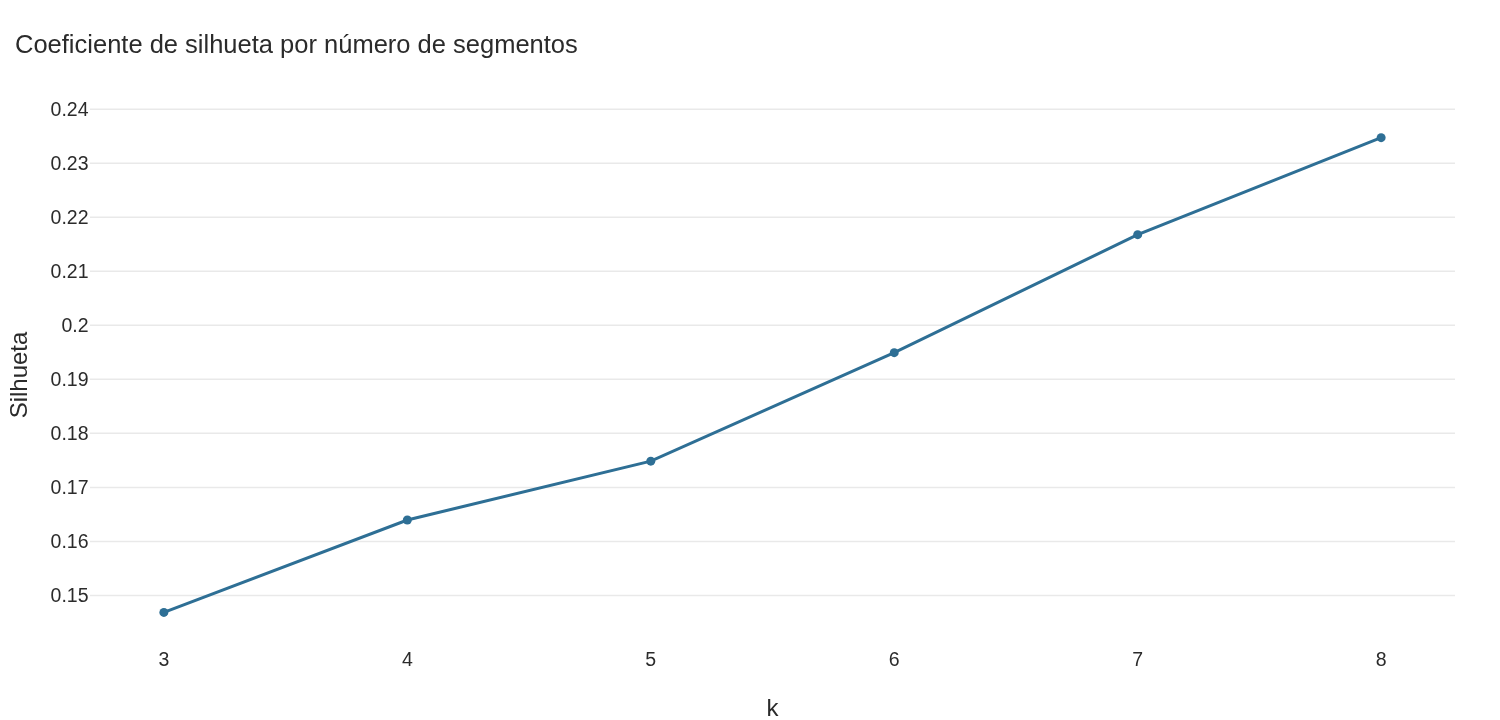

k escolhido: 8 (melhor silhueta com pelo menos 4 grupos acionáveis)


In [3]:
num = ["recencia_dias", "pedidos", "receita", "ticket_medio", "metros_por_pedido", "pct_cupom", "pct_linhas_rolo", "pct_linhas_promo"] + \
      [c for c in X.columns if c.startswith("mix_")]
Z = X[num].copy()
for c in ["pedidos", "receita", "ticket_medio", "metros_por_pedido", "recencia_dias"]:
    Z[c] = np.log1p(Z[c])  # caudas longas
Zs = StandardScaler().fit_transform(Z)

amostra = np.random.default_rng(7).choice(len(Zs), size=min(15000, len(Zs)), replace=False)
sil = {}
for k in range(3, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=7).fit(Zs)
    sil[k] = silhouette_score(Zs[amostra], km.labels_[amostra])
fig = px.line(x=list(sil), y=list(sil.values()), markers=True, title="Coeficiente de silhueta por número de segmentos",
              labels={"x": "k", "y": "Silhueta"})
fig.update_traces(line_color=COR_REAL)
fig.show()
k = max(sil, key=sil.get) if max(sil, key=sil.get) >= 4 else 5
print(f"k escolhido: {k} (melhor silhueta com pelo menos 4 grupos acionáveis)")

In [4]:
km = KMeans(n_clusters=k, n_init=20, random_state=7).fit(Zs)
X["segmento"] = km.labels_
perfil = X.groupby("segmento").agg(
    clientes=("pedidos", "size"), pedidos_medios=("pedidos", "mean"), receita_media=("receita", "mean"),
    ticket_medio=("ticket_medio", "mean"), metros_por_pedido=("metros_por_pedido", "median"),
    recencia_mediana=("recencia_dias", "median"), pct_cupom=("pct_cupom", "mean"), pct_rolo=("pct_linhas_rolo", "mean"),
    pct_promo=("pct_linhas_promo", "mean"), **{c: (c, "mean") for c in X.columns if c.startswith("mix_")})
perfil["pct_receita"] = X.groupby("segmento").receita.sum() / X.receita.sum()
perfil["pct_clientes"] = perfil.clientes / perfil.clientes.sum()

def nomear(r):
    if r.pct_rolo > 0.15 or r.metros_por_pedido > 12:
        return "Atacado / confecção (volume e rolos)"
    if r.pedidos_medios >= 4 and r.recencia_mediana < 240:
        return "Recorrentes de alto valor"
    if r.recencia_mediana > 420:
        return "Inativos de baixo valor"
    if r.pct_cupom > 0.4 or r.pct_promo > 0.35:
        return "Caçadores de promoção"
    top_mix = max([c for c in perfil.columns if c.startswith("mix_")], key=lambda c: r[c])
    return f"Ocasionais - foco em {top_mix.replace('mix_', '')}"

perfil["nome"] = perfil.apply(nomear, axis=1)
dup = perfil["nome"].duplicated(keep=False)
perfil.loc[dup, "nome"] = perfil.loc[dup, "nome"] + " (" + perfil.loc[dup].index.astype(str) + ")"
X["nome_segmento"] = X.segmento.map(perfil["nome"])
cols = ["nome", "clientes", "pct_clientes", "pct_receita", "pedidos_medios", "ticket_medio", "metros_por_pedido",
        "recencia_mediana", "pct_cupom", "pct_rolo"]
perfil.sort_values("pct_receita", ascending=False)[cols].style.format({
    "pct_clientes": "{:.1%}", "pct_receita": "{:.1%}", "pedidos_medios": "{:.1f}", "ticket_medio": "R$ {:,.0f}",
    "metros_por_pedido": "{:.1f}", "recencia_mediana": "{:.0f}", "pct_cupom": "{:.0%}", "pct_rolo": "{:.0%}"})

,nome,clientes,pct_clientes,pct_receita,pedidos_medios,ticket_medio,metros_por_pedido,recencia_mediana,pct_cupom,pct_rolo
segmento,,,,,,,,,,
7,Recorrentes de alto valor,13762,29.2%,59.5%,5.5,R$ 314,6.3,189,14%,0%
5,Atacado / confecção (volume e rolos),1543,3.3%,22.7%,5.4,"R$ 1,148",30.8,195,29%,22%
6,Ocasionais - foco em Algodão,10805,22.9%,4.8%,1.6,R$ 110,2.5,399,25%,0%
3,Ocasionais - foco em Linho,4753,10.1%,3.7%,1.5,R$ 202,3.0,413,27%,0%
2,Ocasionais - foco em Viscose,5707,12.1%,3.1%,1.5,R$ 142,3.0,413,26%,0%
1,Ocasionais - foco em Malha,3835,8.1%,2.6%,1.6,R$ 175,3.0,408,25%,0%
0,Ocasionais - foco em Jeans e Sarja,2465,5.2%,2.0%,1.6,R$ 194,3.5,396,25%,0%
4,Inativos de baixo valor,4223,9.0%,1.6%,1.4,R$ 102,2.5,471,25%,0%


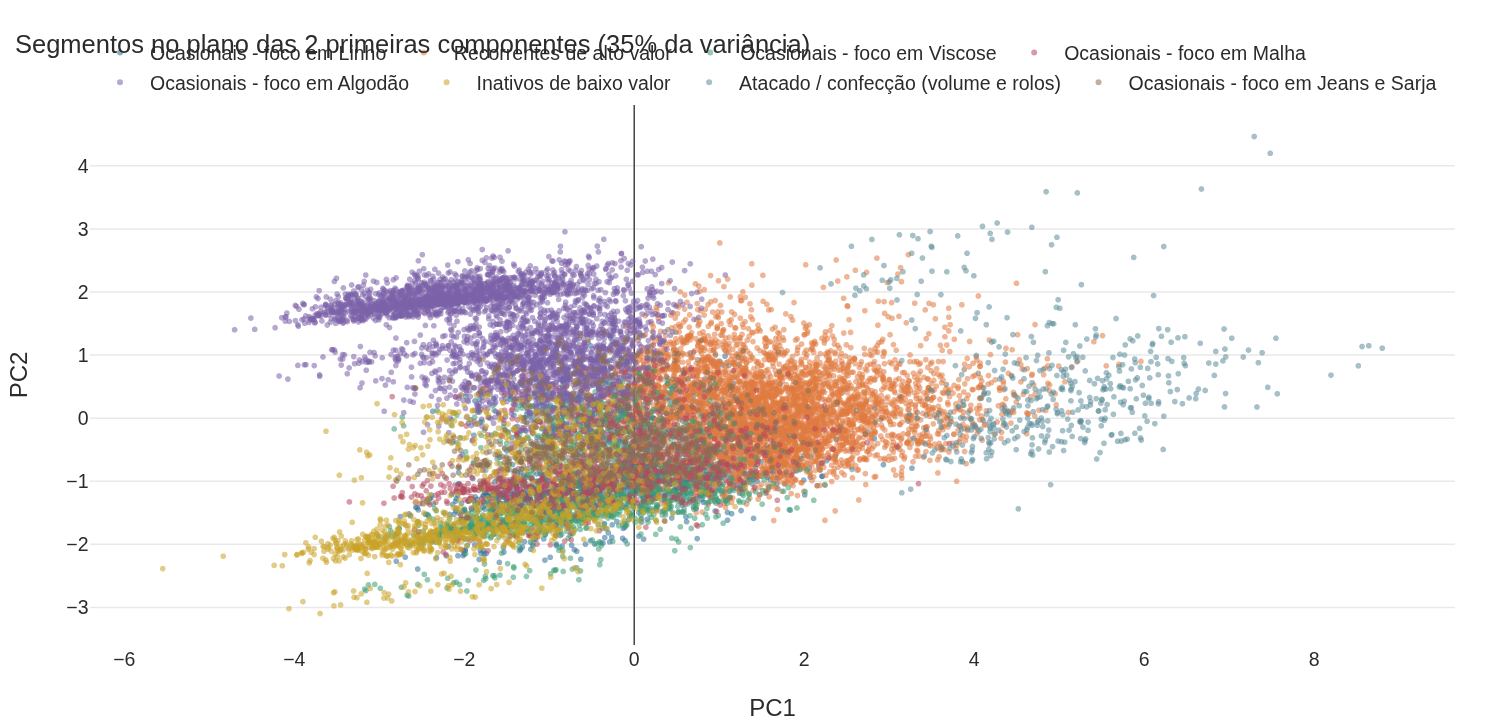

In [5]:
pca = PCA(n_components=2, random_state=7).fit(Zs)
P = pca.transform(Zs[amostra])
fig = px.scatter(x=P[:, 0], y=P[:, 1], color=X["nome_segmento"].values[amostra], opacity=0.55,
                 title=f"Segmentos no plano das 2 primeiras componentes ({pca.explained_variance_ratio_.sum():.0%} da variância)",
                 labels={"x": "PC1", "y": "PC2", "color": ""})
fig.update_traces(marker=dict(size=4))
fig.show()

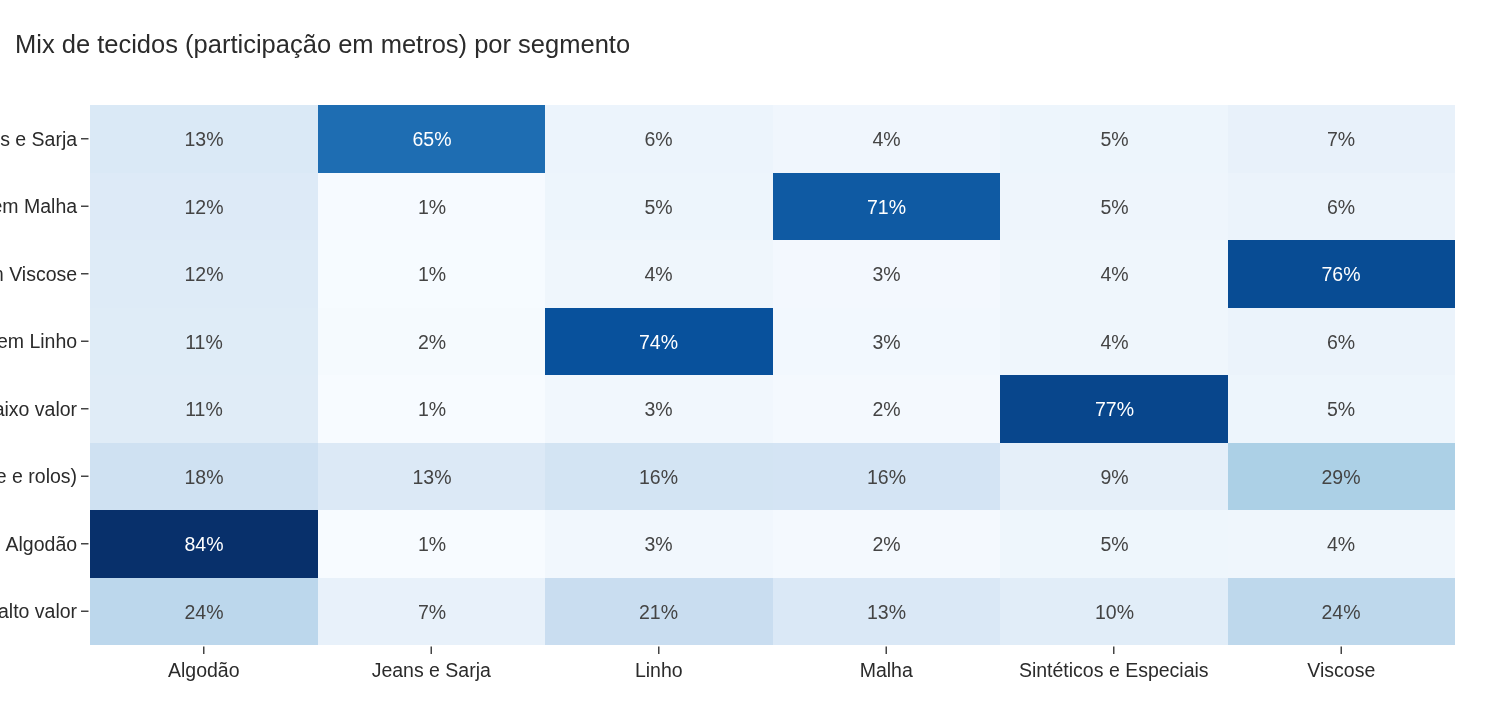

In [6]:
mixcols = [c for c in perfil.columns if c.startswith("mix_")]
hm = perfil.set_index("nome")[mixcols].rename(columns=lambda c: c.replace("mix_", ""))
fig = px.imshow(hm, text_auto=".0%", color_continuous_scale="Blues", aspect="auto",
                title="Mix de tecidos (participação em metros) por segmento")
fig.update_layout(coloraxis_showscale=False, xaxis_title="", yaxis_title="")
fig.show()

## Segmento comportamental x tipo declarado no cadastro

O tipo de cliente é autodeclarado e nem sempre confiável (ex.: costureiras que compram como hobby, ateliês que compram volume). O cruzamento mostra onde o cadastro ajuda e onde o comportamento diz mais.

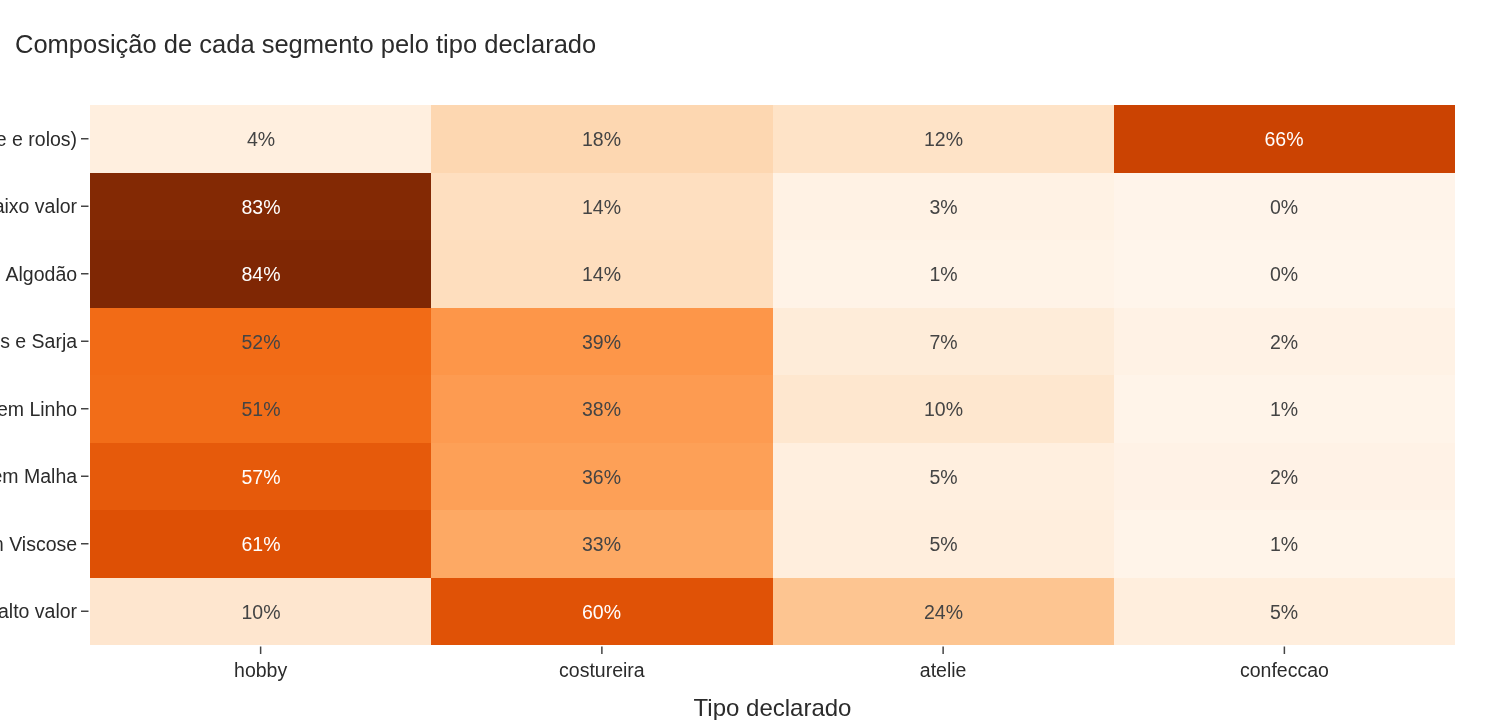

Segmento de maior receita: Recorrentes de alto valor | 29.2% dos clientes e 59.5% da receita


In [7]:
ct = pd.crosstab(X["nome_segmento"], X["tipo_cliente"], normalize="index")
fig = px.imshow(ct[["hobby", "costureira", "atelie", "confeccao"]], text_auto=".0%", color_continuous_scale="Oranges",
                aspect="auto", title="Composição de cada segmento pelo tipo declarado")
fig.update_layout(coloraxis_showscale=False, xaxis_title="Tipo declarado", yaxis_title="")
fig.show()
lider = perfil.sort_values("pct_receita", ascending=False).iloc[0]
print(f"Segmento de maior receita: {lider['nome']} | {lider.pct_clientes:.1%} dos clientes e {lider.pct_receita:.1%} da receita")

## Conclusões de negócio

1. **Dois segmentos sustentam a loja.** As *recorrentes de alto valor* (29% das clientes) fazem 5,5 pedidos em média e trazem 60% da receita. O *atacado/confecção* (3% das clientes) traz 23%, com ticket de R$ 1.148 e 31 metros por pedido. Juntos, 32% das clientes geram 82% da receita.
2. **Atacado pede política própria:** 22% das linhas são rolo e 29% dos pedidos usam cupom, a maior taxa da base. Preço por rolo e tabela por volume tendem a funcionar melhor que cupom genérico, que só reduz margem nesse grupo.
3. **A maioria é ocasional:** 58% das clientes compram 1,5 vez em média, com ticket de R$ 110 a R$ 200 e última compra há mais de um ano. Elas se dividem pelo tecido preferido (algodão, linho, viscose, malha, jeans), o que dá uma régua de CRM simples: comunicar lançamentos e reposições da família que cada uma compra.
4. **Inativas de baixo valor** (9%, última compra há ~16 meses, ticket de R$ 102) não justificam incentivo pago: mantenha só na comunicação orgânica.